<a href="https://colab.research.google.com/github/MLILA05/COU07506-labs/blob/main/COU07506_Week03_240242422800.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 3 — Lab 1B
## Convolution, Correlation and Difference Equations

- Name:DAUDI MUSA MLILA
- Registration number: 240242422800
- Date:25/11/2026
- Group:7

## Pre-lab

## Pre-lab

### (a) Convolution by hand

Given $x[n] = [1, -1, 2]$ and $h[n] = [2, 1, 0, 1]$,
both sequences start at $n = 0$ and are zero outside their listed indices.

**First output sample ($n = 0$)**

$y[0] = x[0]h[0] + x[1]h[-1] + x[2]h[-2]$

Since $h[-1] = h[-2] = 0$, we get $y[0] = 1 \times 2 = 2$.

#### Second output sample ($n = 1$)

$y[1] = x[0]h[1] + x[1]h[0] + x[2]h[-1]$

Since $h[-1] = 0$, the last term is zero.

$y[1] = (1)(1) + (-1)(2) = 1 - 2 = -1$.

#### Third output sample ($n = 2$)

$y[2] = x[0]h[2] + x[1]h[1] + x[2]h[0]$

$y[2] = (1)(0) + (-1)(1) + (2)(2) = 0 - 1 + 4 = 3$.

#### Fourth output sample ($n = 3$)

$y[3] = x[0]h[3] + x[1]h[2] + x[2]h[1]$

$y[3] = (1)(1) + (-1)(0) + (2)(1) = 1 + 0 + 2 = 3$.

#### Fifth output sample ($n = 4$)

$y[4] = x[0]h[4] + x[1]h[3] + x[2]h[2]$

Since $h[4] = 0$, the first term is zero.

$y[4] = (1)(0) + (-1)(1) + (2)(0) = -1$.

#### Sixth output sample ($n = 5$)

$y[5] = x[0]h[5] + x[1]h[4] + x[2]h[3]$

Since $h[5] = h[4] = 0$, only $x[2]h[3]$ contributes.

$y[5] = (2)(1) = 2$.

The complete convolution is $y[n] = [2, -1, 3, 3, -1, 2]$.

### (b) Time-invariance test

The system is $T\{x[n]\} = n x[n]$.

1. Delay the input by one sample, then apply the system.
   The result is $T\{x[n-1]\} = n x[n-1]$.

2. Apply the system first, then delay the output by one sample.
   The result is $y[n-1] = (n-1)x[n-1]$.

At $n=1$, if $x[0]=1$, the first result is $1 \times 1 = 1$
and the second result is $0 \times 1 = 0$.

The two results differ, so the system is time-varying.

## Task 3.1 — Convolution from the definition

In [7]:
import numpy as np

x = [1, -1, 2]
h = [2, 1, 0, 1]

result = np.convolve(x, h)
print(result)

def conv(x, h):
    output_length = len(x) + len(h) - 1
    y = np.zeros(output_length)

    for n in range(output_length):
        for k in range(len(x)):
            h_index = n - k
            if 0 <= h_index < len(h):
                y[n] += x[k] * h[h_index]

    return y

manual_result = conv(x, h)

print("Our function:", manual_result)
print("NumPy:       ", result)
print("Results match:", np.allclose(manual_result, result))
x_example = [1, 2, 3, 1]
h_example = [1, 1, 1]

our_result = conv(x_example, h_example)
numpy_result = np.convolve(x_example, h_example)

print("Our function:", our_result)
print("NumPy:       ", numpy_result)
print("Results match:", np.allclose(our_result, numpy_result))
from time import perf_counter

rng = np.random.default_rng(0)
x_long = rng.standard_normal(2000)
h_long = rng.standard_normal(2000)

start = perf_counter()
our_output = conv(x_long, h_long)
our_time = perf_counter() - start

start = perf_counter()
numpy_output = np.convolve(x_long, h_long)
numpy_time = perf_counter() - start

print(f"Our function: {our_time:.6f} seconds")
print(f"NumPy:        {numpy_time:.6f} seconds")
print(f"Output length: {len(our_output)} samples")
print("Results match:", np.allclose(our_output, numpy_output))

[ 2 -1  3  3 -1  2]
Our function: [ 2. -1.  3.  3. -1.  2.]
NumPy:        [ 2 -1  3  3 -1  2]
Results match: True
Our function: [1. 3. 6. 6. 4. 1.]
NumPy:        [1 3 6 6 4 1]
Results match: True
Our function: 2.961375 seconds
NumPy:        0.002065 seconds
Output length: 3999 samples
Results match: True


My convolution function took 2.961375 seconds, while NumPy took 0.002065 seconds. NumPy was about 1,434 times faster in this run. Both methods produced matching results.

## Task 3.2 — Smoothing a noisy signal by convolution

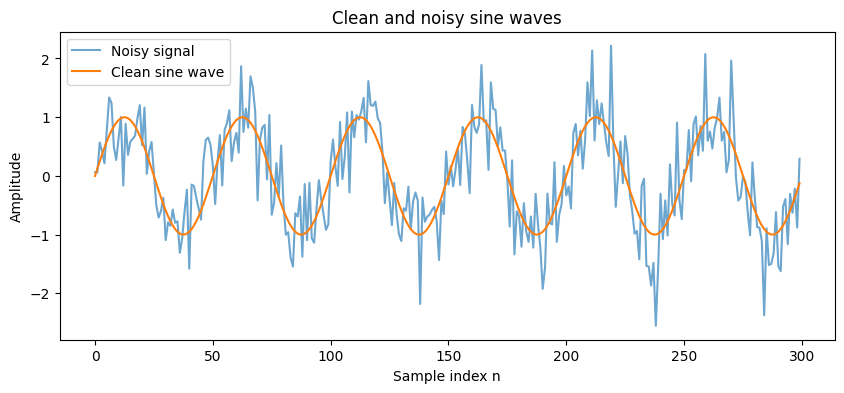

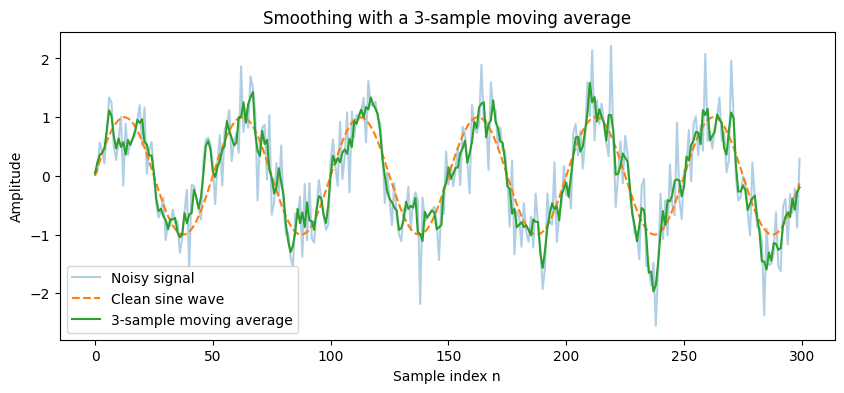

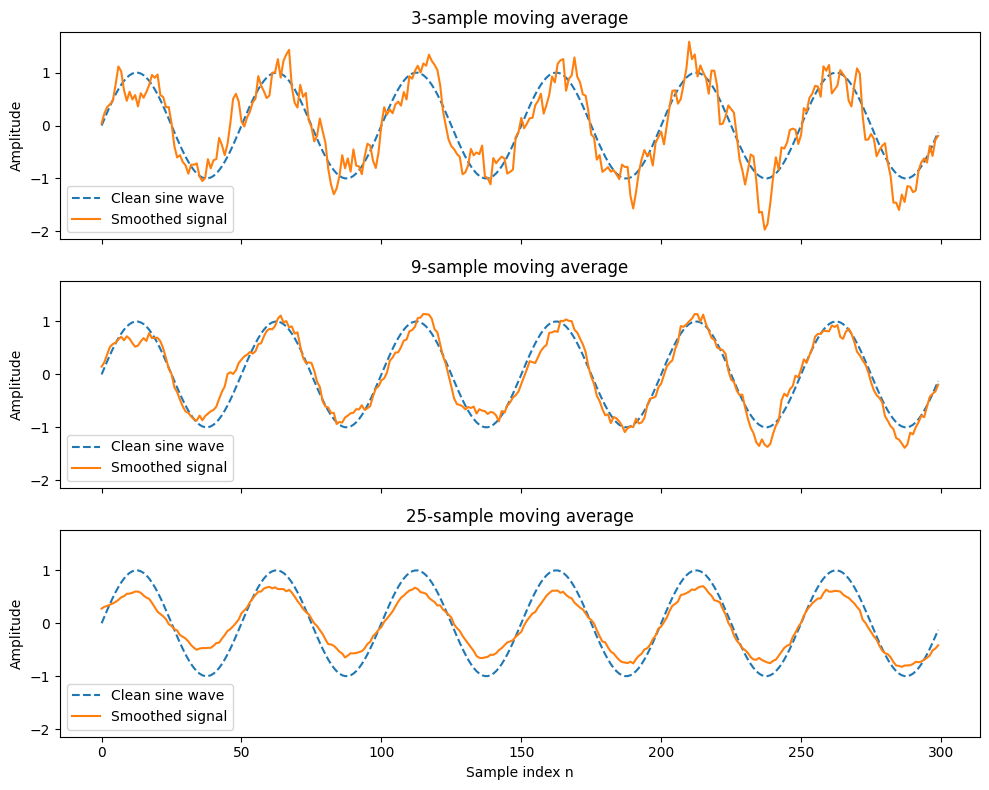

In [10]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
n = np.arange(300)

clean = np.sin(2 * np.pi * n / 50)
noise = 0.5 * rng.standard_normal(len(n))
noisy = clean + noise

plt.figure(figsize=(10, 4))
plt.plot(n, noisy, label="Noisy signal", alpha=0.65)
plt.plot(n, clean, label="Clean sine wave")
plt.title("Clean and noisy sine waves")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.legend()
plt.show()
h3 = np.ones(3) / 3
smoothed_3 = np.convolve(noisy, h3, mode="same")

plt.figure(figsize=(10, 4))
plt.plot(n, noisy, label="Noisy signal", alpha=0.35)
plt.plot(n, clean, "--", label="Clean sine wave")
plt.plot(n, smoothed_3, label="3-sample moving average")
plt.title("Smoothing with a 3-sample moving average")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.legend()
plt.show()
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)

for ax, window in zip(axes, [3, 9, 25]):
    weights = np.ones(window) / window
    smoothed = np.convolve(noisy, weights, mode="same")

    ax.plot(n, clean, "--", label="Clean sine wave")
    ax.plot(n, smoothed, label="Smoothed signal")
    ax.set_title(f"{window}-sample moving average")
    ax.set_ylabel("Amplitude")
    ax.legend()

axes[-1].set_xlabel("Sample index n")
plt.tight_layout()
plt.show()

### Observation

The 3-sample moving average reduced some noise, but the
output was still jagged. The 9-sample moving average gave
a smoother curve and kept the peaks close to the clean
sine wave. The 25-sample moving average gave the smoothest
curve, but it reduced the peak heights noticeably.

For this signal, the 9-sample window gave the best balance
between reducing noise and preserving the sine wave.

## Task 3.3 — Testing linearity and time-invariance

In [15]:
rng = np.random.default_rng(0)
x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)
a, b = 2.0, -3.0

def square_system(x):
    return x**2

# Combine the inputs first, then apply the system.
left = square_system(a * x1 + b * x2)

# Apply the system first, then combine the outputs.
right = a * square_system(x1) + b * square_system(x2)

print("Squaring system is linear:", np.allclose(left, right))
delay = 5

# Delay the input by 5 samples, then square it.
delayed_input = np.concatenate([np.zeros(delay), x1])[:len(x1)]
output_a = square_system(delayed_input)

# Square the original input, then delay the output by 5 samples.
original_output = square_system(x1)
output_b = np.concatenate([np.zeros(delay), original_output])[:len(x1)]

print("Squaring system is time-invariant:", np.allclose(output_a, output_b))
def index_system(x):
    n = np.arange(len(x))
    return n * x

# Linearity: compare the two orders of combining the inputs.
left = index_system(a * x1 + b * x2)
right = a * index_system(x1) + b * index_system(x2)

# Time-invariance: compare delaying the input and delaying the output.
output_a = index_system(delayed_input)
original_output = index_system(x1)
output_b = np.concatenate([np.zeros(delay), original_output])[:len(x1)]

print("Index system is linear:", np.allclose(left, right))
print("Index system is time-invariant:", np.allclose(output_a, output_b))
def moving_average_system(x):
    weights = np.ones(3) / 3
    return np.convolve(x, weights, mode="full")[:len(x)]

# Test linearity.
left = moving_average_system(a * x1 + b * x2)
right = a * moving_average_system(x1) + b * moving_average_system(x2)

# Test time-invariance.
output_a = moving_average_system(delayed_input)
original_output = moving_average_system(x1)
output_b = np.concatenate([np.zeros(delay), original_output])[:len(x1)]

print("Moving average is linear:", np.allclose(left, right))
print("Moving average is time-invariant:", np.allclose(output_a, output_b))


Squaring system is linear: False
Squaring system is time-invariant: True
Index system is linear: True
Index system is time-invariant: False
Moving average is linear: True
Moving average is time-invariant: True


### Task 3.3 results

| System | Linear? | Time-invariant? |
|---|---|---|
| Squaring, $y[n]=x[n]^2$ | No | Yes |
| Index multiplication, $y[n]=n x[n]$ | Yes | No |
| 3-sample moving average | Yes | Yes |

- Squaring changes the effect of scaling. Doubling the input
  before squaring makes the output four times as large.
  Delaying the input simply delays the squared samples.
- Multiplying by $n$ preserves addition and scaling.
  A delayed sample is multiplied by a different index,
  so the system is time-varying.
- The moving average uses the same weights at every sample.
  It preserves addition and scaling, and delaying the input
  delays the output by the same amount.

Only the moving-average system is linear and time-invariant (LTI).

## Task 3.4 — Finding a hidden delay with cross-correlation

Transmitted signal length: 500 samples
Received signal length: 500 samples
Actual delay: 37 samples
Estimated delay: 37 samples


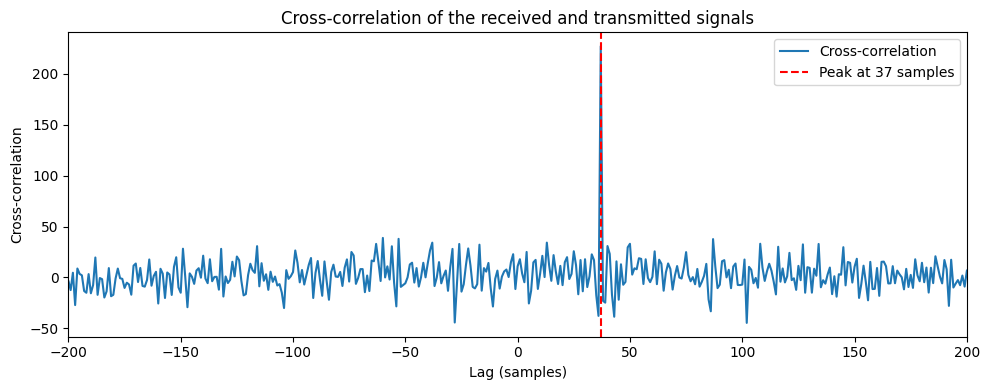

Noise std. dev. | Estimated delay | Correct?
            0.5 |       37 samples | True
              1 |       37 samples | True
              2 |       37 samples | True
              4 |       87 samples | False
Time delay: 37.0 ms
Distance travelled: 12.69 m


In [19]:
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)
true_delay = 37

# Shift the signal right by 37 samples and keep 500 samples.
delayed_signal = np.concatenate([np.zeros(true_delay), 0.6 * x])[:len(x)]

# Add noise to simulate the received signal.
y = delayed_signal + 0.5 * rng.standard_normal(len(x))

print("Transmitted signal length:", len(x), "samples")
print("Received signal length:", len(y), "samples")
print("Actual delay:", true_delay, "samples")
from scipy import signal

correlation = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")

peak_index = np.argmax(correlation)
estimated_delay = lags[peak_index]

print(f"Estimated delay: {estimated_delay} samples")

plt.figure(figsize=(10, 4))
plt.plot(lags, correlation, label="Cross-correlation")
plt.axvline(estimated_delay, color="red", linestyle="--",
            label=f"Peak at {estimated_delay} samples")
plt.xlim(-200, 200)
plt.title("Cross-correlation of the received and transmitted signals")
plt.xlabel("Lag (samples)")
plt.ylabel("Cross-correlation")
plt.legend()
plt.tight_layout()
plt.show()
# Reuse the same noise pattern at each level for a fair comparison.
noise_pattern = (y - delayed_signal) / 0.5

print("Noise std. dev. | Estimated delay | Correct?")

for noise_std in [0.5, 1, 2, 4]:
    noisy_received = delayed_signal + noise_std * noise_pattern
    correlation = signal.correlate(noisy_received, x, mode="full")
    delay_estimate = lags[np.argmax(correlation)]

    print(f"{noise_std:>15g} | {delay_estimate:>8} samples | "
          f"{delay_estimate == true_delay}")
    delay_seconds = estimated_delay / fs
distance_m = 343 * delay_seconds

print(f"Time delay: {delay_seconds * 1000:.1f} ms")
print(f"Distance travelled: {distance_m:.2f} m")

Cross-correlation correctly estimated the delay as 37 samples at noise standard deviations of 0.5, 1, and 2. At 4, the estimate shifted to 87 samples. The correct 37-sample delay corresponds to 37 ms and a sound travel distance of 12.69 m.

## Task 3.5 — Difference equation

In [23]:
impulse = np.zeros(10)
impulse[0] = 1

h_direct = np.zeros(10)

for n in range(10):
    x_previous = impulse[n - 1] if n >= 1 else 0
    y_previous = h_direct[n - 1] if n >= 1 else 0
    y_two_back = h_direct[n - 2] if n >= 2 else 0

    h_direct[n] = (
        impulse[n] + x_previous + 0.75 * y_previous - 0.125 * y_two_back
    )

print("Impulse response:", np.round(h_direct, 6))
from scipy import signal

b = [1, 1]                 # Coefficients of x[n] and x[n-1]
a = [1, -0.75, 0.125]      # Coefficients of y[n], y[n-1], and y[n-2]

h_lfilter = signal.lfilter(b, a, impulse)

print("Loop:   ", np.round(h_direct, 6))
print("lfilter:", np.round(h_lfilter, 6))
print("All 10 samples match:", np.allclose(h_direct, h_lfilter))
n_impulse = np.arange(10)
h_formula = 6 * 0.5**n_impulse - 5 * 0.25**n_impulse

print("Loop:   ", np.round(h_direct, 6))
print("lfilter:", np.round(h_lfilter, 6))
print("Formula:", np.round(h_formula, 6))

print("Loop matches formula:", np.allclose(h_direct, h_formula))
print("lfilter matches formula:", np.allclose(h_lfilter, h_formula))
step_input = np.ones(50)
step_response = signal.lfilter(b, a, step_input)

theoretical_final = sum(b) / sum(a)

print(f"Last step-response sample: {step_response[-1]:.6f}")
print(f"Theoretical final value H(1): {theoretical_final:.6f}")
print("Values match:", np.isclose(step_response[-1], theoretical_final))

Impulse response: [1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
Loop:    [1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
lfilter: [1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
All 10 samples match: True
Loop:    [1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
lfilter: [1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
Formula: [1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
Loop matches formula: True
lfilter matches formula: True
Last step-response sample: 5.333333
Theoretical final value H(1): 5.333333
Values match: True


## Analysis Questions

### 1. Why is NumPy faster, and how many multiplications are needed?

My Python loop took 2.961375 seconds, and NumPy took
0.002065 seconds. NumPy performs the inner calculations
in compiled code, so it avoids the overhead of running
a Python loop for every output sample and checking each index.

For direct convolution, each of the $L$ input samples is
multiplied by each of the $M$ filter samples once. This gives
$L \times M$ multiplications. For my two sequences of length
2,000, that is $2{,}000 \times 2{,}000 = 4{,}000{,}000$
multiplications.

### 2. Which systems are LTI? Could I predict the results before running the code?

Yes. Only the 3-sample moving average is both linear and
time-invariant. I can predict this from the rules of the three systems.

- Squaring is nonlinear because doubling the input makes the
  output four times as large. It is time-invariant because a
  delay shifts the squared samples by the same amount.
- Multiplication by $n$ is linear because it preserves addition
  and scaling. It is time-varying because delaying a sample
  changes the index that multiplies it.
- The moving average is linear because it is a weighted sum.
  It is time-invariant because it uses the same weights at
  every sample index, so an input delay produces the same
  output delay.

  ### 3. Give two engineering applications of cross-correlation in Tanzania

1. **Finding leaks in water pipes.** A water utility can place two
   acoustic sensors on a pipe. Noise from a leak reaches the closer
   sensor first. Cross-correlation estimates the difference in arrival
   time. With the sensor positions and the speed of sound in the pipe,
   engineers can estimate where the leak is.

2. **GPS positioning for land surveying.** A GPS receiver compares the
   signal from each satellite with a copy of that satellite's code.
   The cross-correlation peak shows the shift where the codes align.
   The receiver uses these timing measurements from several satellites
   to calculate its position.


   ### 4. Is the system in Task 3.5 FIR or IIR? Is it stable?

The system is IIR (infinite impulse response). Its impulse response is
$h[n] = 6(0.5)^n - 5(0.25)^n$ for $n \geq 0$. The values get smaller
but remain positive for every finite $n$, so the response continues
indefinitely.

The system is BIBO stable because the sum of the absolute values of
its impulse response is finite. Since $h[n]$ is positive, the sum is

$$
\sum_{n=0}^{\infty} |h[n]|
= \frac{6}{1-0.5} - \frac{5}{1-0.25}
= \frac{16}{3}.
$$

## AI-use statement

I used ChatGPT to explain the Week 3 tasks and help write the Python code.
I checked my convolution by hand against NumPy, verified that
cross-correlation recovered the known delay of 37 samples at the
starting noise level, and compared the impulse response from the loop
with SciPy's lfilter and the closed-form formula.